# Ownership walkthrough: the research system, one step at a time

A teaching notebook for a new owner of this repository. It covers the **research** side
(the matching ladder scored against the A2 final set), not the Streamlit app.
Companion documents: `docs/ownership/01_project_map.md`, `02_design_decisions.md`,
`03_evaluation_and_risks.md`.

**What is scored.** All systems read `text_v2` (D53: no CV `Position`, no metadata). The
rungs shown are the current research candidates:

| Name here | What it is | Code |
|---|---|---|
| TF-IDF | cosine in one shared TF-IDF space, IDF from the A2 train region | `matching.lexical.Tfidf("v2")` |
| SBERT weak | MiniLM fine-tuned on keyword-labelled weak pairs | `matching.sbert.SbertWeak("v2")` |
| X2 | `2·role_match + experience_compatible + 0.999·minmax(TF-IDF)`, all extracted from text | `matching.extracted.ExtractedPlus(Tfidf, "X2")` |
| X4 | X2 with SBERT weak as the text term | `ExtractedPlus(SbertWeak, "X4")` |
| *oracle 1a+2* | the same formula on Djinni's true `Primary Keyword` + experience fields: **not allowed at inference**, shown as a ceiling | `lexical.MetadataPlus(Tfidf("v2"), "1a+2")` |

**Rules this notebook keeps.**
- It **fits nothing**. Every model is loaded from the cache that `checks` / the record
  modules built (D23). The final-set labels are read **for measurement only** (D46).
- Every text excerpt passes `annotation.redact.redact_text` and is truncated. Djinni is
  pre-anonymised, but the rule is applied anyway.
- Probe-style analyses (sections 6, 8, 9) are **exploratory**. They decide nothing and
  are not registered comparisons (AGENTS.md evaluation rule 8).

**Run it.** It needs `data/` built (`data.build --all --seed 0`), the `ml` group, the cached
MiniLM, and the cached SBERT-weak v2 weights and role-family model. A cold cache retrains
them. Warm, it ran in 2.3 minutes on the 22-core development machine; with a cold embedding cache, the first run took about 7 minutes (peak RSS ~3.5 GB).

```bash
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/ownership/walkthrough.ipynb
```

In [1]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from candidate_screener import reporting
from candidate_screener.annotation.redact import redact_text
from candidate_screener.annotation.sample import load_english
from candidate_screener.config import DOCS_DATA, OUTPUT
from candidate_screener.evaluation import final_set, indomain
from candidate_screener.evaluation import retrieval_pilot as rp
from candidate_screener.evidence import evidence as ev
from candidate_screener.evidence import requirements as req
from candidate_screener.extraction import experience, role_family
from candidate_screener.extraction.rules import default_matcher
from candidate_screener.matching import corpus, extracted, lexical, rules, sbert
from candidate_screener.matching.neural import MODEL_ID

warnings.filterwarnings("ignore")
reporting.style(plt)
BLUE, ORANGE, AQUA = reporting.SERIES
INK2, GRID = reporting.TEXT_2, reporting.GRID
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 48)
SEED, V = 0, "v2"
T0 = time.perf_counter()

def excerpt(text, n=400):
    # Redacted, whitespace-collapsed, truncated: the only way document text is printed here.
    return " ".join(redact_text(text).split())[:n] + ("…" if len(str(text)) > n else "")

## 1. Data overview

The corpus is **A2, Djinni**: public JDs and CVs from a Ukrainian / Eastern-European IT job
board. The evaluation uses a 600-pair **final set**: 60 JDs × 10 CVs, labelled Fit / No Fit
by two humans with an LLM tie-breaker (D41). The headline corpus figures below come from
`docs/data/profile-metrics.json` (measured by `data.profile`), not from prose.

In [2]:
prof = json.loads((DOCS_DATA / "profile-metrics.json").read_text())["checks"]["djinni"]
fs = final_set.load()
pairs = corpus.a2_pairs(V)
pairs_v1 = corpus.a2_pairs("v1")
overview = pd.DataFrame({
    "figure": ["Djinni JDs (raw)", "Djinni CVs (raw)", "Primary Keyword families (shared)",
               "final-set pairs", "final-set JDs (generic / targeted)", "final-set CVs",
               "final-set Fit rate", "pairs labelled by both humans", "pairs where the LLM decided"],
    "value": [f"{prof['jds']:,}", f"{prof['cvs']:,}", prof["primary_keyword"]["shared"],
              len(fs), f"{fs.jd_id.nunique()} ({fs[fs.stratum=='generic'].jd_id.nunique()} / "
              f"{fs[fs.stratum=='targeted'].jd_id.nunique()})", fs.cv_id.nunique(),
              f"{(fs.final_label == 'Fit').mean():.1%}", int((fs.n_humans == 2).sum()),
              int((fs.tier == 'llm_breaks_tie').sum())]})
print(overview.to_string(index=False))

                            figure        value
                  Djinni JDs (raw)      141,897
                  Djinni CVs (raw)      210,250
 Primary Keyword families (shared)           41
                   final-set pairs          600
final-set JDs (generic / targeted) 60 (40 / 20)
                     final-set CVs          600
                final-set Fit rate        61.2%
     pairs labelled by both humans          326
       pairs where the LLM decided          107


**Length distributions.** The CV text is shown under `v1` (with the `Position` title, what
annotators read) and `v2` (what systems read). Medians across the whole corpus come from
`profile-metrics.json`.

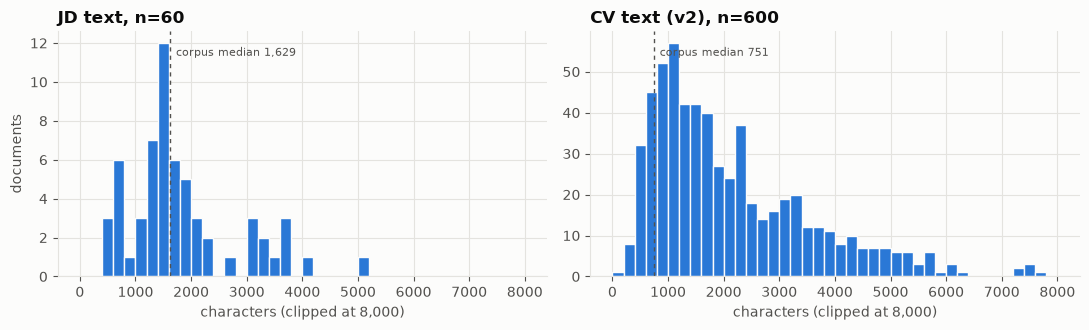

final-set CV median chars: v1 1742, v2 1720; JD median 1550. Shortest v2 CV: 122 chars.


In [3]:
jd_len = pairs.drop_duplicates("jd_id").jd_text.str.len()
cv_len_v2 = pairs.drop_duplicates("cv_id").cv_text.str.len()
cv_len_v1 = pairs_v1.drop_duplicates("cv_id").cv_text.str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
bins = np.linspace(0, 8000, 41)
axes[0].hist(jd_len.clip(upper=8000), bins=bins, color=BLUE, edgecolor=reporting.SURFACE)
axes[0].axvline(prof["jd_chars_median"], color=INK2, ls=(0, (3, 3)), lw=1)
axes[0].set(title=f"JD text, n={len(jd_len)}", xlabel="characters (clipped at 8,000)", ylabel="documents")
axes[0].annotate(f"corpus median {prof['jd_chars_median']:,}", (prof["jd_chars_median"], axes[0].get_ylim()[1]*0.9),
                 xytext=(4, 0), textcoords="offset points", color=INK2, fontsize=8)
axes[1].hist(cv_len_v2.clip(upper=8000), bins=bins, color=BLUE, edgecolor=reporting.SURFACE)
axes[1].axvline(prof["cv_chars_median"], color=INK2, ls=(0, (3, 3)), lw=1)
axes[1].set(title=f"CV text (v2), n={len(cv_len_v2)}", xlabel="characters (clipped at 8,000)")
axes[1].annotate(f"corpus median {prof['cv_chars_median']:,}", (prof["cv_chars_median"], axes[1].get_ylim()[1]*0.9),
                 xytext=(4, 0), textcoords="offset points", color=INK2, fontsize=8)
plt.tight_layout(); plt.show()
print(f"final-set CV median chars: v1 {cv_len_v1.median():.0f}, v2 {cv_len_v2.median():.0f}; "
      f"JD median {jd_len.median():.0f}. Shortest v2 CV: {cv_len_v2.min()} chars.")

**"Parsing" success.** This research path has no resume parser: Djinni ships text fields.
What gets *parsed* is structure extracted from free text. The chart shows, for the final-set
documents, how often each extractor returns something, and, where a ground-truth field exists
(measurement only), how often it is right.

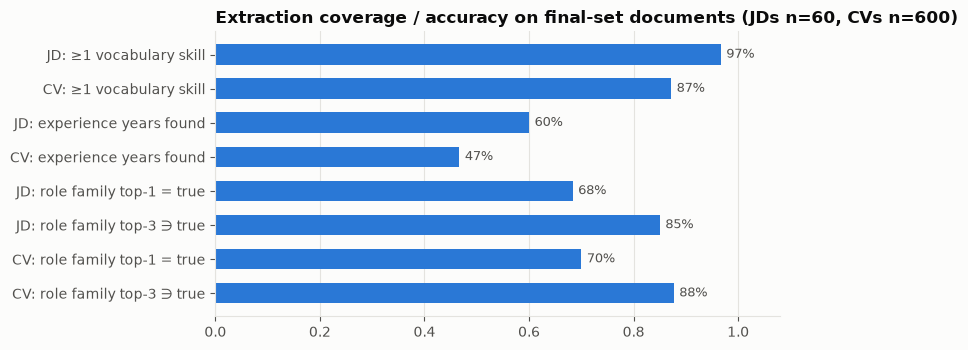

Median vocabulary skills per JD 6, per CV 5


In [4]:
matcher = default_matcher()
role_model = role_family.load_role_model()
jds = pairs.drop_duplicates("jd_id").reset_index(drop=True)
cvs = pairs.drop_duplicates("cv_id").reset_index(drop=True)

jd_years = [experience.jd_experience(t).min_years for t in jds.jd_text]
cv_years = [experience.cv_experience(t).years for t in cvs.cv_text]
jd_skills = [matcher.canonicals(t) for t in jds.jd_text]
cv_skills = [matcher.canonicals(t) for t in cvs.cv_text]

# Oracle role family from the true fields (measurement only) vs the text classifier's top-1/top-3.
labels = list(role_model.labels)
jd_true = role_family.labels_for(pd.DataFrame({"Primary Keyword": jds.jd_keyword, "Position": jds.jd_position}))
cv_true = role_family.labels_for(pd.DataFrame({"Primary Keyword": cvs.cv_keyword, "Position": cvs.cv_position}))
p_jd = role_family.predict_proba(jds.jd_text.tolist(), "jd", role_model)
p_cv = role_family.predict_proba(cvs.cv_text.tolist(), "cv", role_model)
def topk_hit(p, truth, k):
    top = np.argsort(-p, axis=1)[:, :k]
    return np.mean([t in [labels[j] for j in row] for row, t in zip(top, truth)])

cov = pd.DataFrame([
    ("JD: ≥1 vocabulary skill", np.mean([len(s) > 0 for s in jd_skills])),
    ("CV: ≥1 vocabulary skill", np.mean([len(s) > 0 for s in cv_skills])),
    ("JD: experience years found", np.mean([y is not None for y in jd_years])),
    ("CV: experience years found", np.mean([y is not None for y in cv_years])),
    ("JD: role family top-1 = true", topk_hit(p_jd, jd_true, 1)),
    ("JD: role family top-3 ∋ true", topk_hit(p_jd, jd_true, 3)),
    ("CV: role family top-1 = true", topk_hit(p_cv, cv_true, 1)),
    ("CV: role family top-3 ∋ true", topk_hit(p_cv, cv_true, 3)),
], columns=["extractor", "rate"])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(cov.extractor[::-1], cov.rate[::-1], color=BLUE, height=0.6)
for y, v in enumerate(cov.rate[::-1]):
    ax.annotate(f"{v:.0%}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.set(xlim=(0, 1.08), title=f"Extraction coverage / accuracy on final-set documents (JDs n={len(jds)}, CVs n={len(cvs)})")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
print(f"Median vocabulary skills per JD {np.median([len(s) for s in jd_skills]):.0f}, per CV {np.median([len(s) for s in cv_skills]):.0f}")

**One CV, raw vs parsed.** The raw Djinni fields first (`Position` and `Primary Keyword`
are shown as *oracles*: systems never read them), then what the extractors make of the
`v2` text.

In [5]:
_, cv_raw = load_english()
cv_raw = cv_raw.set_index("id")
example_id = cvs.sort_values("cv_id").cv_id.iloc[7]
raw = cv_raw.loc[example_id]
i = cvs.index[cvs.cv_id == example_id][0]
top3 = np.argsort(-p_cv[i])[:3]
exp_ = experience.cv_experience(cvs.cv_text[i])
print("RAW (oracle fields, never inputs)")
print(f"  Position: {raw['Position']!r} | Primary Keyword: {raw['Primary Keyword']!r} | "
      f"Experience Years: {raw['Experience Years']} | English: {raw['English Level']}")
print(f"  CV field excerpt: {excerpt(raw['CV'], 350)}")
print("PARSED from v2 text")
print(f"  {len(cvs.cv_text[i])} chars; vocabulary skills ({len(cv_skills[i])}): {sorted(cv_skills[i])[:12]}")
print(f"  experience: {exp_.years} years from {exp_.source}; band {experience.cv_band(exp_.years)}")
print("  role family top-3: " + ", ".join(f"{labels[j]} {p_cv[i, j]:.2f}" for j in top3)
      + f"  (true: {cv_true[i]})")

RAW (oracle fields, never inputs)
  Position: 'Junior Frontend developer' | Primary Keyword: 'JavaScript' | Experience Years: 0.0 | English: intermediate
  CV field excerpt: Achievement in life and work is the path from a locksmith to the head of a mechanical workshop. In IT, there is a path from student to TeamLead. But with a huge desire to develop further and replenish my experience in coding. The first personal project WebStudio created on FullStack courses in GoIT, all tasks were submitted on time and almost witho…
PARSED from v2 text
  3396 chars; vocabulary skills (2): ['CSS', 'html']
  experience: None years from None; band None
  role family top-3: JavaScript 0.88, Node.js 0.02, Project Manager 0.02  (true: JavaScript)


### What this tells us / open questions

- **The ground truth is small and mixed.** There are 600 pairs, 61% Fit. Only 326 pairs (54%) were labelled by both humans, and the LLM decided 107. Every figure later in this notebook inherits that.
- **Final-set CVs are long for Djinni.** Their median is ~1,720 characters (v2) against a corpus median of 751. JDs are typical (1,550 vs 1,629). The sampling (English, non-empty, 8 of 10 from the JD's keyword) seems to favour richer CVs. *Inferred*: the cause has not been measured.
- **Extraction coverage is the weak link.**
  - Skills: some vocabulary skill is found in 97% of JDs and 87% of CVs, but the medians are only 6 and 5 skills.
  - Experience: years are found in only 60% of JDs and 47% of CVs. X1/X2 count "unknown" as compatible, so the experience term is nearly constant.
  - Role family: the JD's family is wrong about 1 time in 3 (68% top-1), but in the top 3 for 85–88%. Role family is the backbone of X2, so this error rate drives most of its retrieval misses (`16-p7-stage1.md` §6a).
- **The example CV is a junior frontend developer.** The extractors find only `CSS` and `html` in 3,396 characters, no experience figure (Djinni's field says 0 years), and the right role family (0.88). This shows the vocabulary gap from `03` §3: `JS`, `ReactJS` and friends are not in it.

**Open questions.** Does the longer-than-typical CV length in the final set flatter text-similarity systems? Is 47% experience coverage enough to keep an experience term at all?

## 2. One JD, step by step

The JD is picked by rule, not by eye: the `generic` JD whose 10 judged CVs are the most
balanced between Fit and No Fit (ties → smallest id). It is ranked against its **500-candidate
pool** (its 10 judged CVs + 490 random eval-region CVs, `retrieval_pilot.build_pools`).

In [6]:
balance = (fs.assign(fit=fs.final_label.eq("Fit")).groupby(["stratum", "jd_id"]).fit.mean()
           .loc["generic"].sub(0.5).abs().sort_index(kind="stable"))
JD_ID = balance.idxmin()
jd_row = jds.set_index("jd_id").loc[JD_ID]
jd_text = jd_row.jd_text
wanted = req.requirements(jd_text, matcher)
jd_exp = experience.jd_experience(jd_text)
j = jds.index[jds.jd_id == JD_ID][0]
print(f"JD {JD_ID[:10]}…  title (oracle) {jd_row.jd_position!r}, keyword (oracle) {jd_row.jd_keyword!r}")
print(f"Excerpt: {excerpt(jd_text, 500)}")
print(f"\nExtracted requirements ({len(wanted)} vocabulary skills): {[r.canonical for r in wanted][:20]}")
print(f"Experience required: min {jd_exp.min_years} years -> band {experience.jd_band(jd_exp.min_years)}")
print("Role family top-3: " + ", ".join(f"{labels[k]} {p_jd[j, k]:.2f}" for k in np.argsort(-p_jd[j])[:3])
      + f"  (true: {jd_true[j]})")

JD 93ea44b7-0…  title (oracle) 'Senior TechOps(Cloud) Engineer', keyword (oracle) 'DevOps'
Excerpt: Необхідні навички: — 5+ years of experience as Cloud Engineer — Solid experience using Google Cloud products — Experience with Kubernetes — Solid experience in automate continuous delivery (CI/CD) using Jenkins — Linux/Unix environment solid foundation — Experience in automation/configuration management using Terraform — Experience with microservices using Docker — Experience with Nginx and Nginx Service Mesh — Knowledge of Data pipelines and processing tools, including BigQuery — Experience wit…

Extracted requirements (8 vocabulary skills): ['kubernetes', 'Jenkins (tools for software configuration management)', 'linux', 'unix', 'terraform', 'docker', 'bigquery', 'Agile development']
Experience required: min 5.0 years -> band 4-6
Role family top-3: DevOps 0.92, Sysadmin 0.03, Other/other 0.01  (true: DevOps)


In [7]:
pools = rp.build_pools(SEED, V)
pool = pools[pools.jd_id == JD_ID].reset_index(drop=True)
x1 = extracted.ExtractedRule(role_model); x1.fit(None)
x2 = extracted.ExtractedPlus(lexical.Tfidf(V), "X2", rule=x1); x2.fit(None)
tf = x2.text
comp = x1.components(pool)
pool = pool.assign(
    x2=x2.score(pool).to_numpy(), role=comp.role_match.to_numpy(), exp=comp.experience_compatible.to_numpy(),
    tfidf=tf.score(pool).to_numpy())
lab = fs.set_index("pair_id").final_label
pool["label"] = pool.pair_id.map(lab).fillna("unjudged")
pool["rank"] = pool.x2.rank(ascending=False, method="first").astype(int)
cols = ["rank", "cv", "x2", "role", "exp", "tfidf", "label"]
view = pool.assign(cv=pool.cv_id.str[:8]).sort_values("rank")[cols].round(3)
print("Top 10 of 500 (X2)"); print(view.head(10).to_string(index=False))
print("\nBottom 5 of 500"); print(view.tail(5).to_string(index=False))
print("\nWhere the 10 judged CVs landed:", sorted(pool.loc[pool.label != "unjudged", "rank"].tolist()))

Top 10 of 500 (X2)
 rank       cv    x2  role  exp  tfidf    label
    1 64b3a954 3.781 0.891    1  0.161 unjudged
    2 9b3c414b 3.640 0.919    1  0.129 unjudged
    3 60fe6ab2 3.497 0.918    1  0.106 unjudged
    4 8d31878b 3.471 0.918    1  0.102      Fit
    5 cdd0a889 3.436 0.919    1  0.096 unjudged
    6 0782979e 3.406 0.840    1  0.117      Fit
    7 9448f69d 3.352 0.909    1  0.086      Fit
    8 5be00ea1 3.334 0.914    1  0.081   No Fit
    9 cc9013f6 3.327 0.906    1  0.083 unjudged
   10 648dd04e 3.307 0.866    1  0.092 unjudged

Bottom 5 of 500
 rank       cv    x2  role  exp  tfidf    label
  496 71ecb688 0.124 0.001    0  0.020 unjudged
  497 c13a0cc1 0.123 0.000    0  0.020 unjudged
  498 2324b823 0.106 0.004    0  0.016 unjudged
  499 8817c6bb 0.088 0.002    0  0.013 unjudged
  500 2ff85435 0.080 0.003    0  0.012 unjudged

Where the 10 judged CVs landed: [4, 6, 7, 8, 26, 31, 167, 237, 432, 457]


### What this tells us / open questions

- **The English filter is leaky.** This JD's text opens with a Ukrainian heading ("Необхідні навички") but passed the publisher's English tag. Mixed-language postings exist in the evaluation set.
- **JD extraction looks sensible here:** 8 vocabulary skills, the experience requirement (5 years → band 4-6), and the right role family (DevOps, 0.92). Some ESCO canonical names are odd for a recruiter ("Jenkins (tools for software configuration management)").
- **Ranking.** All 5 judged Fits rank inside the top 31 of 500 (ranks 4, 6, 7, 26, 31). Four of the 5 No Fits rank 167–457, but one No Fit sits at **#8** among the Fits. That gives a per-JD AUC of 23/25 = 0.92 for this JD.
- **6 of the top 10 are unjudged.** Nobody knows whether they are good. Recall metrics silently count them as not Fit, and precision on the pool would count them as errors.
- **The bottom 5** have role ≈ 0 and no experience match: other families. That part is easy.

**Open questions.** How good are the unjudged CVs that X2 puts above judged Fits? A small extra labelling round on top-ranked unjudged CVs would turn the pool recall into a real precision estimate.

## 3. Score distribution

X2 is a sum of a role term (×2), a 0/1 experience term and a text term in [0, 0.999]. So its
histogram is not one blob: it shows structure. The dashed line is the **top-50 shortlist cut**,
the only threshold in the research pipeline (S2 asks how many Fits survive it). The judged
CVs are marked by label.

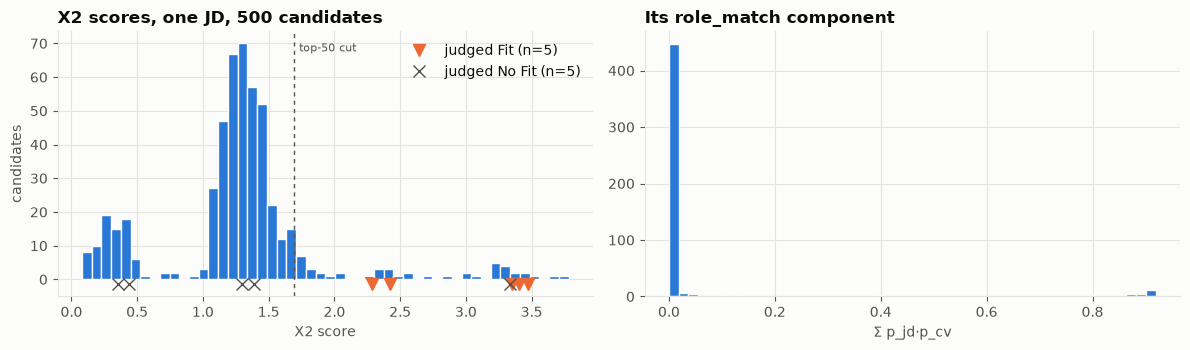

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
cut = pool.sort_values("rank").x2.iloc[49]
axes[0].hist(pool.x2, bins=50, color=BLUE, edgecolor=reporting.SURFACE)
axes[0].axvline(cut, color=INK2, ls=(0, (3, 3)), lw=1)
axes[0].annotate("top-50 cut", (cut, axes[0].get_ylim()[1] * 0.92), xytext=(4, 0), textcoords="offset points", color=INK2, fontsize=8)
for lbl, color, mk in (("Fit", ORANGE, "v"), ("No Fit", INK2, "x")):
    xs = pool.loc[pool.label == lbl, "x2"]
    axes[0].plot(xs, np.full(len(xs), -1.5), mk, color=color, ms=8, label=f"judged {lbl} (n={len(xs)})")
axes[0].set(title=f"X2 scores, one JD, 500 candidates", xlabel="X2 score", ylabel="candidates")
axes[0].legend(loc="upper right")
axes[1].hist(pool.role, bins=50, color=BLUE, edgecolor=reporting.SURFACE)
axes[1].set(title="Its role_match component", xlabel="Σ p_jd·p_cv")
plt.tight_layout(); plt.show()

Same view over **all 59 scoreable JDs**: scores are min–max scaled within each JD, because
raw scores are comparable within one JD only. Split by the final label. Only the judged
600 pairs are shown here.

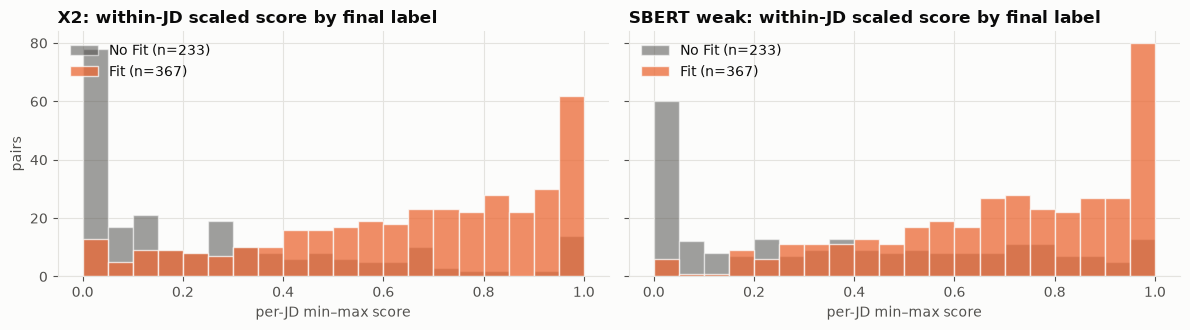

In [9]:
all_x2 = x2.score(pairs)
sw = sbert.SbertWeak(V); sw.fit(None)
all_sw = sw.score(pairs)
def per_jd_minmax(s, jd):
    g = pd.DataFrame({"s": s.to_numpy(), "jd": jd.to_numpy()}).groupby("jd").s
    lo, hi = g.transform("min"), g.transform("max")
    return ((pd.DataFrame({"s": s.to_numpy()}).s - lo) / (hi - lo).replace(0, 1)).to_numpy()
y = pairs.pair_id.map(lab).eq("Fit").to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (name, s) in zip(axes, (("X2", all_x2), ("SBERT weak", all_sw))):
    z = per_jd_minmax(s, pairs.jd_id)
    b = np.linspace(0, 1, 21)
    ax.hist(z[~y], bins=b, color=INK2, alpha=0.55, label=f"No Fit (n={(~y).sum()})", edgecolor=reporting.SURFACE)
    ax.hist(z[y], bins=b, color=ORANGE, alpha=0.75, label=f"Fit (n={y.sum()})", edgecolor=reporting.SURFACE)
    ax.set(title=f"{name}: within-JD scaled score by final label", xlabel="per-JD min–max score")
    ax.legend(loc="upper left")
axes[0].set_ylabel("pairs"); plt.tight_layout(); plt.show()

### What this tells us / open questions

- **For one JD, X2 is not a blob but three shelves:**
  - ~0.3: wrong role, experience unknown or incompatible;
  - ~1.3: wrong role, experience compatible;
  - above 3: right role.
- **`role_match` behaves almost like a hard switch for this JD.** About 450 of 500 CVs score ≈ 0 and a dozen score ≈ 0.9, with almost nothing in between. The top-50 cut (1.7) therefore lands inside the *wrong-role* shelf. Slots ~15–50 are filled by TF-IDF ordering among other roles, which is the mechanism `16-p7-stage1.md` §6a describes.
- **Over all 59 JDs (judged pairs only)**, both systems separate Fit from No Fit but with heavy overlap. Much of the separation comes from a pile of No Fits at the very bottom of their JD (the off-family candidates), not from fine ordering among plausible candidates. That matches the gap between overall and within-family AUC in §7.
- **There is no threshold to mark.** Scores are comparable within a JD only. No research system produces a calibrated Fit probability.

**Open questions.** Should the role term be treated explicitly as a filter with a fallback (top-k families), rather than a soft weight? The shortlist-recall Z rungs (weight 32–64) point that way.

## 4. Explainability per candidate

Two views for the walkthrough JD's top-ranked candidates:
1. **Score breakdown**: X2's three additive parts: `2·role_match`, `experience_compatible`,
   `0.999·minmax(TF-IDF)`.
2. **Requirement evidence**: for each JD vocabulary skill, `matched` (the CV names it),
   `supported` (a CV sentence has MiniLM cosine ≥ τ = 0.28, `output/evidence/tau.json`) or
   `missing` (`evidence.gather`). The evidence layer does **not** feed the score. It is shown
   beside it, as in the app.

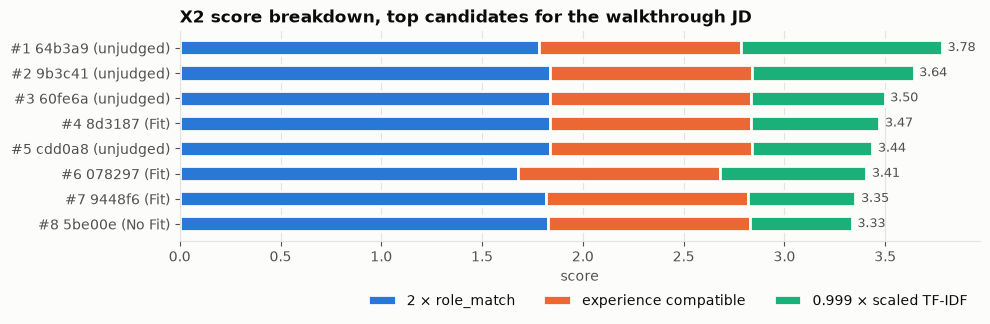

In [10]:
TOPN = 8
top = pool.sort_values("rank").head(TOPN).copy()
lo, hi = pool.tfidf.min(), pool.tfidf.max()
top["text_part"] = 0.999 * (top.tfidf - lo) / (hi - lo if hi > lo else 1)
top["role_part"] = 2 * top.role
fig, ax = plt.subplots(figsize=(10, 3.6))
names = [f"#{r} {c[:6]} ({l})" for r, c, l in zip(top["rank"], top.cv_id, top.label)]
left = np.zeros(TOPN)
for part, color, label in (("role_part", BLUE, "2 × role_match"), ("exp", ORANGE, "experience compatible"),
                           ("text_part", AQUA, "0.999 × scaled TF-IDF")):
    ax.barh(names[::-1], top[part].to_numpy()[::-1], left=left[::-1], color=color, label=label,
            height=0.6, edgecolor=reporting.SURFACE, linewidth=2)
    left = left + top[part].to_numpy()
for yy, v in enumerate(left[::-1]):
    ax.annotate(f"{v:.2f}", (v, yy), xytext=(4, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.set(title="X2 score breakdown, top candidates for the walkthrough JD", xlabel="score")
ax.legend(loc="lower right", ncol=3, bbox_to_anchor=(1, -0.38)); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

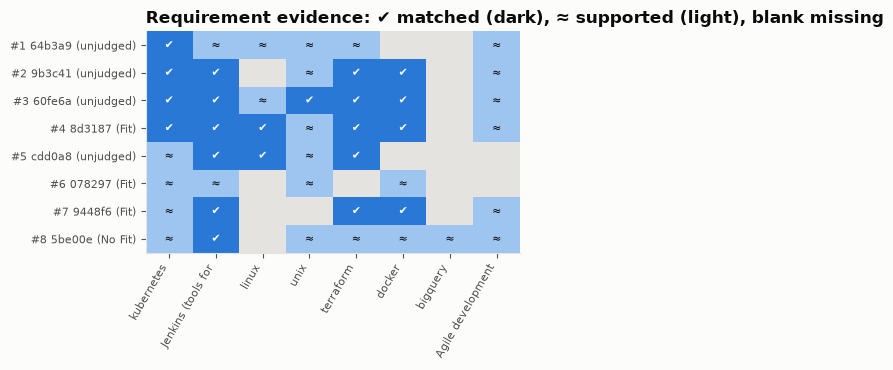

coverage per candidate: {'#1': 0.75, '#2': 0.75, '#3': 0.88, '#4': 0.88, '#5': 0.62, '#6': 0.5, '#7': 0.62, '#8': 0.88}
Of requirement cells without a name match, 60% are marked 'supported' (25/42).
Example: requirement 'Agile development' 'supported' by (cos 0.37): “DevOps practice is a hobby for me”
Weakest: requirement 'Jenkins (tools for software configuration management)' 'supported' by (cos 0.30): “DevOps practice is a hobby for me”


In [11]:
encoder = sbert.Encoder(MODEL_ID, "minilm-zero-shot-evidence")
status_code = {"missing": 0, "supported": 1, "matched": 2}
grid_rows = []
for _, row in top.iterrows():
    found = ev.gather(wanted, row.cv_text, matcher, encoder)
    grid_rows.append([status_code[e.status] for e in found])
grid = np.array(grid_rows)
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(min(14, 1 + 0.55 * len(wanted)), 3.8))
ax.imshow(grid, cmap=ListedColormap([GRID, "#9ec5f0", BLUE]), aspect="auto", vmin=0, vmax=2)
ax.set_xticks(range(len(wanted)), [r.canonical[:18] for r in wanted], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(TOPN), names, fontsize=8); ax.grid(False)
for (r, c), v in np.ndenumerate(grid):
    ax.text(c, r, "✔" if v == 2 else ("≈" if v == 1 else ""), ha="center", va="center", fontsize=8,
            color=reporting.SURFACE if v == 2 else reporting.TEXT)
ax.set_title("Requirement evidence: ✔ matched (dark), ≈ supported (light), blank missing")
plt.tight_layout(); plt.show()
print("coverage per candidate:", {n.split()[0]: float(v) for n, v in zip(names, (grid > 0).mean(axis=1).round(2))})
not_matched = grid[grid < 2]
print(f"Of requirement cells without a name match, {np.mean(not_matched == 1):.0%} are marked 'supported' "
      f"({int((not_matched == 1).sum())}/{not_matched.size}).")
# One 'supported' quote, so a reader can judge whether the support is real.
for _, row in top.iterrows():
    sup = [e for e in ev.gather(wanted, row.cv_text, matcher, encoder) if e.status == "supported"]
    if sup:
        e = max(sup, key=lambda e: e.similarity)
        print(f"Example: requirement {e.requirement!r} 'supported' by (cos {e.similarity:.2f}): “{excerpt(e.quote, 200)}”")
        e = min(sup, key=lambda e: e.similarity)
        print(f"Weakest: requirement {e.requirement!r} 'supported' by (cos {e.similarity:.2f}): “{excerpt(e.quote, 200)}”")
        break

### What this tells us / open questions

- **Within the right role, X2 is just TF-IDF.** For the top 8, the role part (≈ 1.7–1.8) and the experience part (1) are near-identical. The order among them is decided entirely by the scaled TF-IDF slice. The "rule + text" design puts no other signal there.
- **Coverage does not separate Fit from No Fit.** The No Fit at #8 has requirement coverage 0.88, as high as the best Fits.
- **"Supported" fires too easily.** 60% (25 of 42) of requirement cells without a name match are marked `supported`. The printed example shows why: the one sentence "DevOps practice is a hobby for me" is taken as evidence for both *Agile development* (cos 0.37) and *Jenkins* (cos 0.30). τ = 0.28 was calibrated against **random** SkillSpan sentences (easy negatives), so on in-domain CVs, where every sentence is topically close, it accepts vague sentences as evidence.
- The evidence layer never feeds the score. It is an explanation that can disagree with the ranking.

**Open questions.** Hand-check ~50 `supported` cells to estimate their precision before the report claims evidence-grounded explanations. Should τ be re-calibrated on in-domain hard negatives (CV sentences from the same role that do not mention the skill)?

## 5. Embedding map

t-SNE of the walkthrough JD's 500-candidate pool in **SBERT-weak (v2)** space, with the JD
embedded alongside and plotted as a star. Left: coloured by X2 score (sequential, one hue).
Right: coloured by the CVs' *true* role family (oracle, measurement only), top 3 families
plus "other". t-SNE distorts global distances, so read neighbourhoods, not distances. Its
seed is fixed.

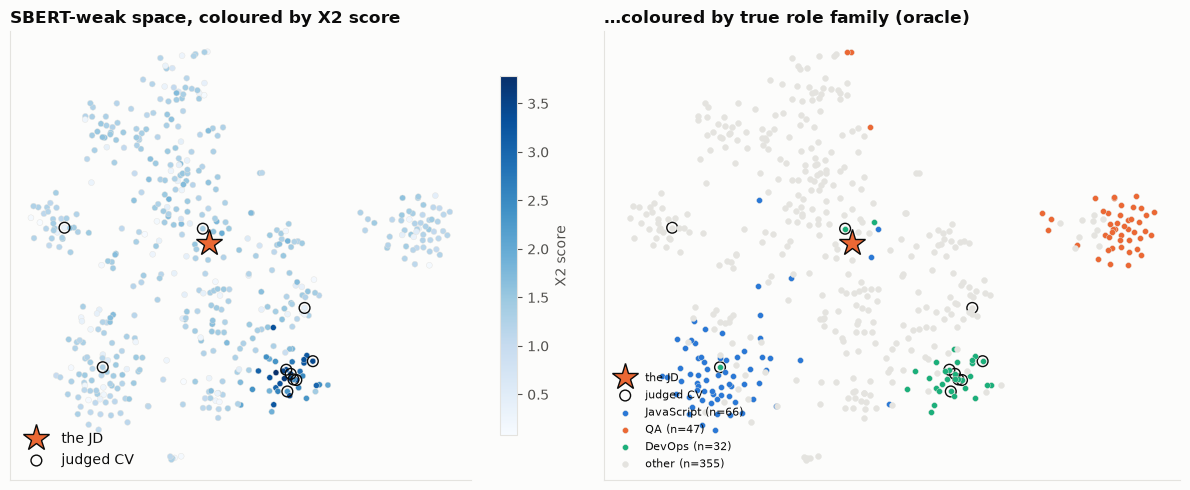

JD true family: DevOps; CVs in pool with that family: 32


In [12]:
from sklearn.manifold import TSNE
emb_cv = sw.encoder.encode(pool.cv_text)
emb_jd = sw.encoder.encode([jd_text])
xy = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(np.vstack([emb_cv, emb_jd]))
pool_true = role_family.labels_for(pd.DataFrame({"Primary Keyword": pool.cv_keyword,
                                                 "Position": pool.cv_id.map(cv_raw.Position)}))
fam_top = pool_true.value_counts().index[:3].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = axes[0].scatter(xy[:-1, 0], xy[:-1, 1], c=pool.x2, cmap="Blues", s=18, edgecolor=GRID, linewidth=0.3)
plt.colorbar(sc, ax=axes[0], label="X2 score", shrink=0.8)
for ax in axes:
    ax.plot(xy[-1, 0], xy[-1, 1], "*", ms=20, color=ORANGE, markeredgecolor=reporting.TEXT, label="the JD")
    judged = (pool.label != "unjudged").to_numpy()
    ax.scatter(xy[:-1][judged, 0], xy[:-1][judged, 1], facecolors="none", edgecolors=reporting.TEXT, s=60, lw=1, label="judged CV")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0].set_title("SBERT-weak space, coloured by X2 score"); axes[0].legend(loc="lower left")
for fam, color in zip(fam_top + ["other"], [BLUE, ORANGE, AQUA, GRID]):
    m = pool_true.isin([fam]).to_numpy() if fam != "other" else ~pool_true.isin(fam_top).to_numpy()
    axes[1].scatter(xy[:-1][m, 0], xy[:-1][m, 1], s=18, color=color, label=f"{fam} (n={m.sum()})", edgecolor=GRID, linewidth=0.3)
axes[1].set_title("…coloured by true role family (oracle)"); axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
print(f"JD true family: {jd_true[j]}; CVs in pool with that family: {(pool_true == jd_true[j]).sum()}")

### What this tells us / open questions

- **SBERT-weak space is organised by role family.** QA, JavaScript and DevOps form clean, separate clusters. That is exactly what its keyword-labelled training pairs taught it (`02` §1.10).
- **High X2 scores coincide with the DevOps cluster**, the JD's true family. Most judged CVs sit in or near it, and a few are scattered elsewhere.
- **The JD star does not sit in its own family's cluster.** A JD and a CV are different kinds of text, so a JD embeds away from the CVs it matches, even though their cosine is what the system uses. This is a t-SNE plot, so treat it as a hint about neighbourhoods, not a measurement.
- Within the DevOps cluster, no visible structure separates Fit from No Fit. That is consistent with within-family AUC ≈ 0.70–0.75.

**Open questions.** Is a role-organised embedding what we want for the *second* stage, where all candidates already share the role? A model trained to separate candidates *within* a family (e.g. on the LLM batch's within-JD pairs, R3) is the natural test; R3 tied SBERT weak.

## 6. JD × candidate heatmap: does the ranking depend on the JD?

Score **every final-set JD against every final-set CV** (60 × 600 = 36,000 pairs; only 600
are labelled). If a system ranked by "generic CV quality" or by length, the same CVs would
win for every JD. Rows (JDs) and columns (CVs) are sorted by true role family (oracle), so a
JD-specific system shows **diagonal blocks**. Values are within-JD percentiles. *Exploratory.*

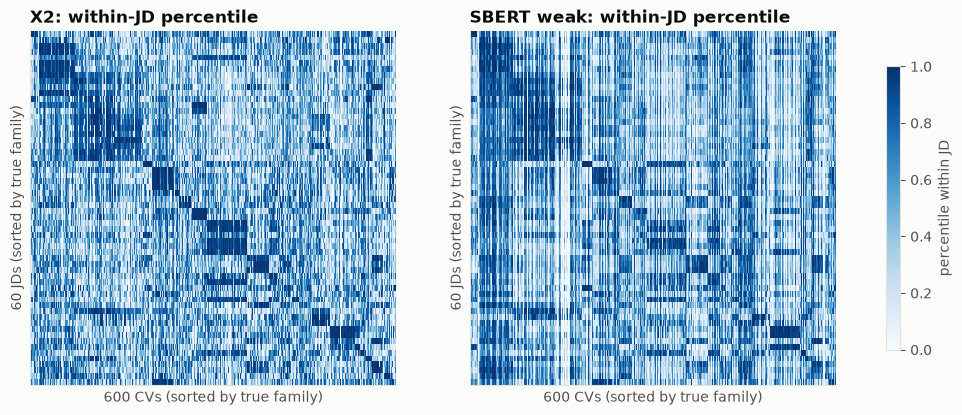

How many of the 60 JDs put each CV in their top 10 (expected mean 1.0):
       X2  SBERT weak
mean  1.0         1.0
50%   1.0         0.0
max   8.0        11.0
X2: share of each JD's top 10 (of 600) sharing its true family: 0.64
SBERT weak: share of each JD's top 10 (of 600) sharing its true family: 0.48


In [13]:
grid_pairs = pd.DataFrame([(a, b) for a in jds.jd_id for b in cvs.cv_id], columns=["jd_id", "cv_id"])
grid_pairs = grid_pairs.assign(pair_id=grid_pairs.jd_id + "__" + grid_pairs.cv_id,
                               jd_text=grid_pairs.jd_id.map(jds.set_index("jd_id").jd_text),
                               cv_text=grid_pairs.cv_id.map(cvs.set_index("cv_id").cv_text))
gx2 = x2.score(grid_pairs).to_numpy()
gsw = sw.score(grid_pairs).to_numpy()
jd_order = np.argsort(np.array(jd_true, dtype=str), kind="stable")
cv_order = np.argsort(np.array(cv_true, dtype=str), kind="stable")
def pct_matrix(scores):
    m = scores.reshape(len(jds), len(cvs))
    return (m.argsort(axis=1).argsort(axis=1) / (len(cvs) - 1))[jd_order][:, cv_order]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (name, s) in zip(axes, (("X2", gx2), ("SBERT weak", gsw))):
    im = ax.imshow(pct_matrix(s), aspect="auto", cmap="Blues", interpolation="nearest")
    ax.set(title=f"{name}: within-JD percentile", xlabel="600 CVs (sorted by true family)", ylabel="60 JDs (sorted by true family)")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8, label="percentile within JD")
plt.show()
def hubness(scores, k=10):
    m = scores.reshape(len(jds), len(cvs))
    top = np.argsort(-m, axis=1)[:, :k]
    return np.bincount(top.ravel(), minlength=len(cvs))
hub = pd.DataFrame({"X2": hubness(gx2), "SBERT weak": hubness(gsw)})
print("How many of the 60 JDs put each CV in their top 10 (expected mean 1.0):")
print(hub.describe().loc[["mean", "50%", "max"]].round(2).to_string())
same = np.array([[a == b for b in cv_true] for a in jd_true])
for name, s in (("X2", gx2), ("SBERT weak", gsw)):
    m = s.reshape(len(jds), len(cvs)); top = np.argsort(-m, axis=1)[:, :10]
    print(f"{name}: share of each JD's top 10 (of 600) sharing its true family: "
          f"{np.mean([same[r, top[r]].mean() for r in range(len(jds))]):.2f}")

### What this tells us / open questions

- **Rankings do differ by JD, mostly by role.** X2's heatmap shows diagonal blocks: JDs of a family rank CVs of that family high. In each JD's top 10 (of 600), 64% share the JD's true family for X2 and 48% for SBERT weak.
- **SBERT weak has vertical stripes, i.e. "hub" CVs.** One CV is in the top 10 for 11 of 60 JDs, while the median CV is in no JD's top 10. Part of SBERT weak's score is a JD-independent "this looks like a strong IT CV" component. X2's role term dampens this (max 8).
- Hubs matter for a shortlist product: the same few candidates would be recommended for many unrelated roles.

**Open questions.** What makes a hub? Candidates are length, generic buzzword density and English fluency. A quick correlation of hub count with CV length is the first check.

## 7. Evaluation plots

**7a. Committed headline figures.** Per-JD AUC with 95% JD-bootstrap CIs, read from
`output/matching/stage1-metrics.json` (not recomputed). Overall AUC beside **within-family**
AUC: within-family counts only the candidates sharing the JD's true keyword, which is the
"is this a *good* candidate for the right role" question.

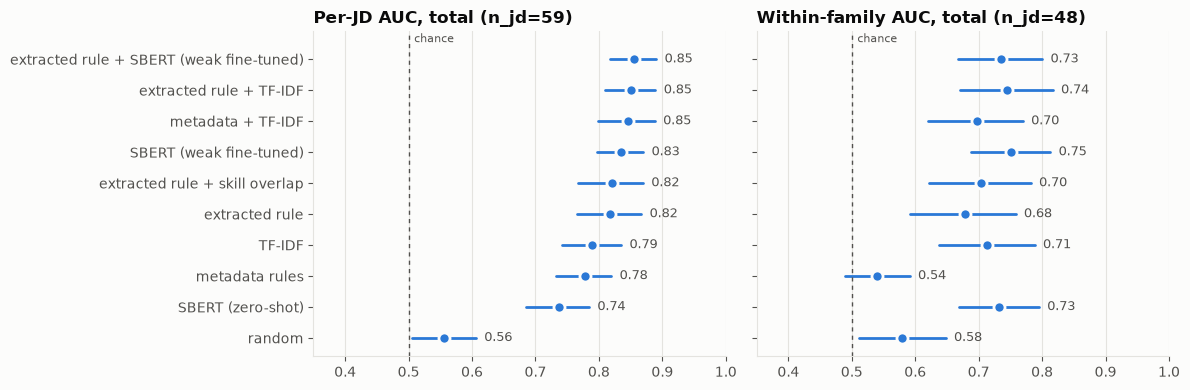

In [14]:
rec = json.loads((OUTPUT / "matching" / "stage1-metrics.json").read_text())
def fig_of(block, metric, scope="total", subset="all"):
    return next(f for f in block["figures"] if f["metric"] == metric and f["scope"] == scope and f["subset"] == subset)
rows = []
for name, block in rec["systems"].items():
    for metric in ("auc", "within_family_auc"):
        f = fig_of(block, metric)
        rows.append((name, metric, f["value"], f["ci_low"], f["ci_high"], f["n_jd"]))
auc = pd.DataFrame(rows, columns=["system", "metric", "value", "low", "high", "n_jd"])
order = auc[auc.metric == "auc"].sort_values("value").system.tolist()[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric, title in zip(axes, ("auc", "within_family_auc"), ("Per-JD AUC, total", "Within-family AUC, total")):
    d = auc[auc.metric == metric].set_index("system").loc[order]
    reporting.dot_ci(ax, d.index.tolist(), d.value.tolist(), d.low.tolist(), d.high.tolist(), ref=0.5, ref_label="chance")
    ax.set(title=f"{title} (n_jd={int(d.n_jd.iloc[0])})", xlim=(0.35, 1.0))
plt.tight_layout(); plt.show()

**7b. Recall@k and precision@k.** Recall@k is over the 500-candidate pools of all scoreable
JDs, using the project's own `retrieval_pilot.recall_at`. Precision@k is within each JD's
**10 judged CVs** (k ≤ 10). Pool precision would count the 490 unjudged distractors as No
Fit, which is a lower bound. The oracle uses Djinni's true fields and is not an allowed system.

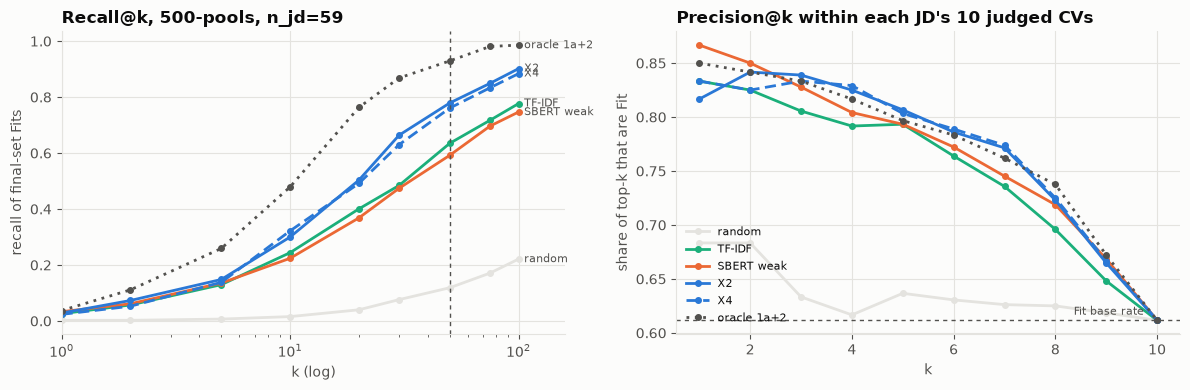

    random  TF-IDF  SBERT weak     X2     X4  oracle 1a+2
10   0.016   0.244       0.224  0.300  0.322        0.479
50   0.119   0.635       0.592  0.779  0.761        0.929


In [15]:
from candidate_screener.evaluation import retrieval_pilot
rel = rp.relevant(pools)
x4 = extracted.ExtractedPlus(sbert.SbertWeak(V), "X4", rule=x1); x4.fit(None)
oracle = lexical.MetadataPlus(lexical.Tfidf(V), "1a+2"); oracle.fit(None)
systems = {"random": rules.Random(SEED), "TF-IDF": tf, "SBERT weak": sw, "X2": x2, "X4": x4, "oracle 1a+2": oracle}
systems["random"].fit(None)
pool_scores = {n: s.score(pools) for n, s in systems.items()}
KS = [1, 2, 5, 10, 20, 30, 50, 75, 100]
recall = pd.DataFrame({n: [rp.recall_at(pools, sc, rel, k).mean() for k in KS] for n, sc in pool_scores.items()}, index=KS)
judged_scores = {n: s.score(pairs) for n, s in systems.items()}
def precision_at(scores, k):
    d = pd.DataFrame({"jd": pairs.jd_id, "s": scores.to_numpy(), "y": y, "pid": pairs.pair_id})
    return d.sort_values(["jd", "s", "pid"], ascending=[True, False, True]).groupby("jd").head(k).groupby("jd").y.mean().mean()
PK = list(range(1, 11))
prec = pd.DataFrame({n: [precision_at(sc, k) for k in PK] for n, sc in judged_scores.items()}, index=PK)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
styles = {"random": (GRID, "-"), "TF-IDF": (AQUA, "-"), "SBERT weak": (ORANGE, "-"), "X2": (BLUE, "-"),
          "X4": (BLUE, (0, (4, 2))), "oracle 1a+2": (INK2, (0, (1, 2)))}
for n in systems:
    c, ls = styles[n]
    axes[0].plot(KS, recall[n], color=c, ls=ls, lw=2, marker="o", ms=4, label=n)
    axes[1].plot(PK, prec[n], color=c, ls=ls, lw=2, marker="o", ms=4, label=n)
    axes[0].annotate(n, (KS[-1], recall[n].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
axes[0].axvline(50, color=INK2, lw=1, ls=(0, (3, 3)))
axes[0].set(xscale="log", title=f"Recall@k, 500-pools, n_jd={rp.recall_at(pools, pool_scores['X2'], rel, 10).size}", xlabel="k (log)", ylabel="recall of final-set Fits", xlim=(1, 160))
axes[1].axhline(y.mean(), color=INK2, lw=1, ls=(0, (3, 3)))
axes[1].annotate("Fit base rate", (10, y.mean()), xytext=(-60, 4), textcoords="offset points", fontsize=8, color=INK2)
axes[1].set(title="Precision@k within each JD's 10 judged CVs", xlabel="k", ylabel="share of top-k that are Fit")
axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
print(recall.loc[[10, 50]].round(3).to_string())

**7c. False positives and false negatives (X2, judged CVs only).** FP = a No Fit CV ranked
in its JD's top 2 of 10; FN = a Fit CV ranked 9th or 10th. Up to 5 of each, chosen by the
largest error margin. The *why* column is a **rule-generated** reading of the components and
label provenance (`role`, `exp`, oracle families, tier), not a human diagnosis.

In [16]:
d = pairs.assign(x2=all_x2.to_numpy(), y=y, tier=pairs.pair_id.map(fs.set_index("pair_id").tier),
                 yc=pairs.pair_id.map(fs.set_index("pair_id").yc_raw), van=pairs.pair_id.map(fs.set_index("pair_id").van_raw))
cmp_ = x1.components(pairs); d["role"], d["exp"] = cmp_.role_match.to_numpy(), cmp_.experience_compatible.to_numpy()
d["jd_fam"] = d.jd_id.map(dict(zip(jds.jd_id, jd_true))); d["cv_fam"] = d.cv_id.map(dict(zip(cvs.cv_id, cv_true)))
d["r"] = d.groupby("jd_id").x2.rank(ascending=False, method="first")
def why(r):
    out = []
    if r.tier == "llm_breaks_tie": out.append("humans split→LLM")
    elif r.tier == "single_human": out.append("1 annotator")
    same = r.jd_fam == r.cv_fam
    if r.y and not same: out.append("cross-family Fit")
    if r.y and same and r.role < 0.2: out.append("role extractor missed")
    if not r.y and same and r.role >= 0.5: out.append("right role, No Fit for unseen reasons")
    if not r.y and not same and r.role >= 0.5: out.append("role extractor confused")
    return "; ".join(out) or "text similarity"
fp = d[(~d.y) & (d.r <= 2)].sort_values("x2", ascending=False).head(5)
fn = d[(d.y) & (d.r >= 9)].sort_values("x2").head(5)
cols = ["jd", "cv", "rank", "role", "exp", "jd_fam", "cv_fam", "yc", "van", "why"]
for title, t in (("False positives", fp), ("False negatives", fn)):
    t = t.assign(jd=t.jd_id.str[:6], cv=t.cv_id.str[:6], rank=t.r.astype(int), why=t.apply(why, axis=1))
    print(f"{title} ({len(d[(~d.y) & (d.r <= 2)]) if title.startswith('False p') else len(d[(d.y) & (d.r >= 9)])} in total; 5 shown)")
    print(t[cols].round(2).to_string(index=False, max_colwidth=60)); print()

False positives (19 in total; 5 shown)
    jd     cv  rank  role  exp           jd_fam           cv_fam            yc    van                                                     why
ba3439 00d2b6     1  0.94    1    QA Automation    QA Automation        No Fit    NaN      1 annotator; right role, No Fit for unseen reasons
d13583 b9b966     1  0.69    1 Business Analyst Business Analyst Potential Fit No Fit humans split→LLM; right role, No Fit for unseen reasons
df5bda 4be663     1  0.68    1       JavaScript       JavaScript        No Fit    NaN      1 annotator; right role, No Fit for unseen reasons
cd34e6 057da7     2  0.78    1            Sales            Sales Potential Fit No Fit humans split→LLM; right role, No Fit for unseen reasons
21a58a 0be96e     2  0.18    1           Python           Python        No Fit    NaN                                             1 annotator

False negatives (20 in total; 5 shown)
    jd     cv  rank  role  exp           jd_fam           cv_fam     

### What this tells us / open questions

- **AUC (committed record).** The top four (X4, X2, metadata + TF-IDF, SBERT weak) all sit at 0.83–0.85 with overlapping CIs; no ranking among them is supported. **Within family** everything drops to 0.68–0.75. SBERT weak, with no role term, is the best within family (0.75). The metadata rule is at chance there (0.54).
- **Recall@k on the pools.**
  - X2/X4 beat TF-IDF and SBERT weak clearly (Recall@50 0.78 / 0.76 vs 0.64 / 0.59), but stay far below the oracle (0.93). The oracle uses fields that are not allowed.
  - Recall@10 is ~0.30 for the best allowed system: 7 in 10 Fits are not in the top 10 of 500. Caveat: some of the 490 unjudged CVs above them may be real Fits.
- **Precision@k within the 10 judged.** Every non-random system puts a Fit first 82–87% of the time, against a 61% base rate. The systems are nearly indistinguishable, and precision@10 equals the base rate by construction.
- **False positives / negatives (X2).** 19 FP and 20 FN.
  - Most FPs are right-role CVs labelled No Fit, often by one annotator or by the LLM after a human split. The score has no signal for whatever made them No Fit (seniority, depth, domain).
  - FNs are either the role extractor missing the role (role ≈ 0 for a same-family CV) or cross-family Fits that the role term punishes, e.g. a JavaScript CV for a Node.js JD.
  - Several FNs are pairs where `van` said Good Fit and `yc` said No Fit: label noise, not system error.

**Open questions.** Should adjacent families (Node.js ↔ JavaScript, QA ↔ QA Automation) share credit in the role term? What signal would catch "right role, still No Fit"? The annotation guide's reasons for No Fit are the place to look.

## 8. Sensitivity tests

Take one judged **Fit** CV for the walkthrough JD, perturb it, and re-rank it inside its
500-pool (the other 499 CVs unchanged). Perturbations:

| Variant | What changes |
|---|---|
| `+ JD skills` | append "Skills: " + the JD's vocabulary skills (keyword stuffing) |
| `+ negated skills` | append "I have no experience with " + the same skills |
| `− Highlights` | drop the `Highlights` field (a missing section) |
| `first half only` | keep the first half of the text (a truncated parse) |
| `+ name` | prepend a person's name |
| `+ JD title` | prepend the JD's own title (the leak D53 removed from fields) |

Then the stuffing test is repeated over 20 JDs × their judged CVs for an aggregate. *Exploratory.*

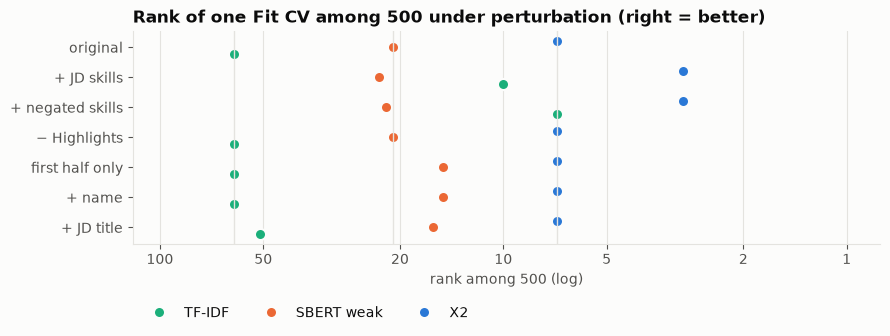

                  TF-IDF  SBERT weak  X2
variant                                 
original              61          21   7
+ JD skills           10          23   3
+ negated skills       7          22   3
− Highlights          61          21   7
first half only       61          15   7
+ name                61          15   7
+ JD title            51          16   7


In [17]:
fit_cvs = pool[(pool.label == "Fit")].sort_values("rank")
target = fit_cvs.iloc[len(fit_cvs) // 2]
raw_t = cv_raw.loc[target.cv_id]
skills_line = ", ".join(r.text for r in wanted)
no_highlights = corpus.build_cv_text(pd.DataFrame([raw_t.drop(labels=[]).to_dict() | {"Highlights": ""}]), V).iloc[0]
variants = {
    "original": target.cv_text,
    "+ JD skills": target.cv_text + "\nSkills: " + skills_line,
    "+ negated skills": target.cv_text + "\nI have no experience with " + skills_line + ".",
    "− Highlights": no_highlights,
    "first half only": target.cv_text[: len(target.cv_text) // 2],
    "+ name": "Olena Kovalenko\n" + target.cv_text,
    "+ JD title": f"{jd_row.jd_position}\n" + target.cv_text,
}
rank_rows = []
for vname, text in variants.items():
    frame = pool.copy(); frame.loc[frame.cv_id == target.cv_id, "cv_text"] = text
    row = {"variant": vname}
    for sname, s in (("TF-IDF", tf), ("SBERT weak", sw), ("X2", x2)):
        sc = s.score(frame).to_numpy()
        k = int(np.where(frame.cv_id == target.cv_id)[0][0])
        row[sname] = int((sc > sc[k]).sum() + 1)
    rank_rows.append(row)
ranks = pd.DataFrame(rank_rows).set_index("variant")
fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(ranks))[::-1]
for (sname, color), off in zip((("TF-IDF", AQUA), ("SBERT weak", ORANGE), ("X2", BLUE)), (-0.22, 0, 0.22)):
    ax.plot(ranks[sname], yy + off, "o", color=color, ms=8, label=sname, markeredgecolor=reporting.SURFACE, markeredgewidth=1.5)
for sname in ranks.columns:
    ax.axvline(ranks.loc["original", sname], color=GRID, lw=1)
from matplotlib.ticker import FixedLocator, NullLocator
ax.set_yticks(yy, ranks.index); ax.set_xscale("log"); ax.invert_xaxis()
ticks = [1, 2, 5, 10, 20, 50, 100]
ax.xaxis.set_major_locator(FixedLocator(ticks)); ax.xaxis.set_minor_locator(NullLocator()); ax.set_xticklabels([str(t) for t in ticks])
ax.set_xlim(120, 0.8)
ax.set(title="Rank of one Fit CV among 500 under perturbation (right = better)", xlabel="rank among 500 (log)")
ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, -0.42)); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(ranks.to_string())

In [18]:
rows = []
for jd_id, g in list(pairs.groupby("jd_id", sort=True))[:20]:
    jt = g.jd_text.iloc[0]
    skills = ", ".join(r.text for r in req.requirements(jt, matcher))
    stuffed = g.assign(cv_text=g.cv_text + "\nSkills: " + skills, pair_id=g.pair_id + "__stuffed")
    both = pd.concat([g, stuffed], ignore_index=True)
    for sname, s in (("TF-IDF", tf), ("SBERT weak", sw), ("X2", x2)):
        sc = pd.Series(s.score(both).to_numpy(), index=both.pair_id)
        best_orig = sc.loc[g.pair_id].max()
        for pid in g.pair_id:
            rows.append((sname, jd_id, sc[pid + "__stuffed"] - sc[pid], sc[pid + "__stuffed"] > best_orig))
stuff = pd.DataFrame(rows, columns=["system", "jd", "delta", "beats_best_original"])
print(stuff.groupby("system").agg(n=("delta", "size"), mean_delta=("delta", "mean"),
                                  share_beats_best=("beats_best_original", "mean")).round(3).to_string())

              n  mean_delta  share_beats_best
system                                       
SBERT weak  200       0.041             0.215
TF-IDF      200       0.052             0.330
X2          200       0.329             0.255


### What this tells us / open questions

- **Keyword stuffing works, and negation is invisible.** For this CV, appending the JD's skills moves TF-IDF from rank 61 → 10 and X2 from 7 → 3. Appending "I have **no** experience with" + the same skills does the *same* (TF-IDF 61 → 7, X2 7 → 3). No system reads negation.
- **SBERT weak barely reacts to stuffing for this CV** (21 → 23). Over 20 JDs (200 CVs), the stuffed CV still beats the JD's best original CV in **33% (TF-IDF), 26% (X2) and 22% (SBERT weak)** of cases. X2's mean Δ is large (0.33) because the skill words also raise `role_match`: the role classifier reads skills too.
- **The robustness tests move SBERT, not X2.** Removing `Highlights` changes nothing: this CV's Highlights field is apparently empty (*inferred* from the identical ranks). Truncating to the first half or prepending a name moves SBERT weak 21 → 15, and X2 does not move.
- **The title leak D53 removed still pays.** Prepending the JD's own title helps SBERT (21 → 16) and TF-IDF (61 → 51).

**Open questions.** A stuffing / negation guard (e.g. down-weight bare skill lists, detect negated mentions) needs a registered test before it can be claimed. Should robustness probes like these become invariant tests in `tests/`?

## 9. Bias probe

Djinni is pre-anonymised: no names, gender, age or nationality fields exist, so no
group-fairness audit is possible on the labels (`evaluation/group_gaps.py` docstring). Two
probes instead:

1. **Name swap (counterfactual).** Prepend one name line to every final-set CV and re-score.
   Ten names in five name-origin groups, two each. A name-blind system shows Δ = 0. Caveats:
   any name is out of distribution for Djinni, and two names per group cannot separate
   "origin" from "these two strings".
2. **Proxy groups that do exist** (oracle fields, measurement only): the CV's English level
   and its experience band. Does a **Fit** CV's within-JD standing differ by group?

*Exploratory.*

In [19]:
NAMES = {"Ukrainian": ["Olena Kovalenko", "Andrii Shevchenko"], "Anglo": ["Emily Johnson", "James Smith"],
         "Arabic": ["Fatima Al-Sayed", "Mohammed Haddad"], "Chinese": ["Wang Fang", "Li Wei"],
         "Indian": ["Priya Sharma", "Rahul Gupta"]}
base = {"TF-IDF": tf.score(pairs).to_numpy(), "SBERT weak": all_sw.to_numpy(), "X2": all_x2.to_numpy()}
rows = []
for group, names in NAMES.items():
    for nm in names:
        f = pairs.assign(cv_text=nm + "\n" + pairs.cv_text, pair_id=pairs.pair_id + "__" + nm)
        for sname, s in (("TF-IDF", tf), ("SBERT weak", sw), ("X2", x2)):
            sc = s.score(f).to_numpy()
            delta = sc - base[sname]
            moved = 0
            for jd_id, idx in pairs.groupby("jd_id").indices.items():
                b = base[sname][idx]
                for k, i in enumerate(idx):
                    others = np.delete(b, k)
                    moved += int((others > b[k]).sum() != (others > sc[i]).sum())
            rows.append((sname, group, nm, delta.mean(), np.abs(delta).max(), moved))
names_df = pd.DataFrame(rows, columns=["system", "group", "name", "mean_delta", "max_abs_delta", "rank_moved_of_600"])
summary = names_df.groupby(["system", "group"]).agg(mean_delta=("mean_delta", "mean"),
                                                    max_abs_delta=("max_abs_delta", "max"),
                                                    rank_moved=("rank_moved_of_600", "mean")).round(4)
print(summary.to_string())
sd = pd.Series(base["SBERT weak"]).groupby(pairs.jd_id.to_numpy()).std().mean()
print(f"\nFor scale: mean within-JD SD of SBERT-weak scores = {sd:.3f}")

                      mean_delta  max_abs_delta  rank_moved
system     group                                           
SBERT weak Anglo          0.0006         0.1557       151.0
           Arabic         0.0013         0.1609       160.5
           Chinese        0.0008         0.0983       161.0
           Indian         0.0041         0.1547       151.5
           Ukrainian      0.0031         0.1576       158.0
TF-IDF     Anglo          0.0000         0.0000         0.0
           Arabic         0.0000         0.0000         0.0
           Chinese        0.0000         0.0000         0.0
           Indian         0.0000         0.0000         0.0
           Ukrainian      0.0000         0.0000         0.0
X2         Anglo         -0.0021         0.0891         4.5
           Arabic        -0.0015         0.1205         5.0
           Chinese       -0.0009         0.0976         5.0
           Indian        -0.0015         0.0795         4.0
           Ukrainian     -0.0015        

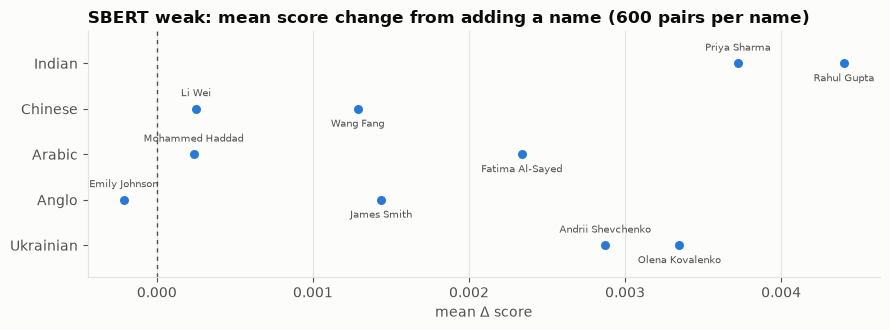

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.4))
s = names_df[names_df.system == "SBERT weak"]
groups = list(NAMES)
for k, g in enumerate(groups):
    v = s[s.group == g]
    ax.plot(v.mean_delta, [k] * len(v), "o", color=BLUE, ms=8, markeredgecolor=reporting.SURFACE, markeredgewidth=1.5)
    for n_, (_, r) in enumerate(v.sort_values("mean_delta").iterrows()):
        ax.annotate(r["name"], (r.mean_delta, k), xytext=(0, 9 if n_ == 0 else -13), textcoords="offset points",
                    ha="center", fontsize=7, color=INK2)
ax.axvline(0, color=INK2, lw=1, ls=(0, (3, 3)))
ax.set_yticks(range(len(groups)), groups); ax.grid(axis="y", visible=False); ax.set_ylim(-0.7, len(groups) - 0.3)
ax.set(title="SBERT weak: mean score change from adding a name (600 pairs per name)", xlabel="mean Δ score")
plt.tight_layout(); plt.show()

In [21]:
pct = pd.Series(per_jd_minmax(all_sw, pairs.jd_id), index=pairs.pair_id)
pct_x2 = pd.Series(per_jd_minmax(all_x2, pairs.jd_id), index=pairs.pair_id)
fits = pairs[y].assign(eng=lambda t: t.cv_id.map(cv_raw["English Level"]), band=lambda t: t.cv_exp_band,
                        sbert=lambda t: t.pair_id.map(pct), x2=lambda t: t.pair_id.map(pct_x2))
for col, title in (("eng", "English level (CV field)"), ("band", "experience band (CV field)")):
    t = fits.groupby(col).agg(n=("pair_id", "size"), sbert_mean=("sbert", "mean"), x2_mean=("x2", "mean")).round(3)
    print(f"Fit CVs, within-JD scaled score by {title}:"); print(t.to_string()); print()

Fit CVs, within-JD scaled score by English level (CV field):
                n  sbert_mean  x2_mean
eng                                   
basic           2       0.279    0.620
fluent        105       0.762    0.645
intermediate  101       0.637    0.611
pre            20       0.648    0.656
upper         138       0.721    0.698

Fit CVs, within-JD scaled score by experience band (CV field):
        n  sbert_mean  x2_mean
band                          
0-1    68       0.590    0.597
2-3   122       0.691    0.646
4-6    90       0.759    0.716
7+     87       0.750    0.654



### What this tells us / open questions

- **TF-IDF is name-blind here.** The names are not in its 5,000-term vocabulary, so Δ = 0. That is an accident of vocabulary size, not a design guarantee.
- **SBERT weak is not name-blind.** Mean shifts are tiny (≤ 0.0045, against a within-JD SD of 0.080) and no group is pushed down. But single-pair shifts reach 0.16, and **150–160 of 600 CVs change position among their 10 peers for every name group**. That is arbitrary sensitivity, not a demonstrated group bias: two names per group cannot separate "origin" from "these strings", and Djinni CVs never carry names. X2 moves only 4–5 of 600.
- **Proxy groups (Fit CVs only, within-JD scaled score).**
  - English level: SBERT weak scores Fits with *intermediate* English (0.64, n = 101) below *fluent* (0.76, n = 105) and *upper* (0.72, n = 138); basic has n = 2, so ignore it.
  - Experience: Fits with 0–1 years score lower (0.59) than those with 4–6 (0.76).
  - X2 is flatter on both (0.61–0.70).
  - This may be legitimate (English and experience are real job requirements; the JDs ask for them) or a proxy (fluency → longer, more polished CVs → higher similarity). It is **not** controlled for length here.

**Open questions.** A proper counterfactual suite needs many names per group, pronoun / gender swaps and a length control. Should the system strip a name or header block before scoring? Is the English-level gradient among *Fit* candidates acceptable for a screening aid?

## Summary for the new owner

1. **The task the benchmark measures is mostly "right role?".** Every allowed system reaches ~0.85 AUC, but within a role family it is 0.68–0.75. Section 5 shows the embedding space is organised by role, and section 6 shows the rankings are role blocks plus SBERT "hubs".
2. **X2's weakness is the role extractor, not the formula's text term.** The role family is wrong for ~1 in 3 JDs, and `role_match` acts like a switch. When it is wrong, the shortlist fills with other roles ordered by TF-IDF (§3, §7c).
3. **Inside the right role, nothing beyond text similarity is used.** X2 = TF-IDF there (§4). Experience is unknown for half the documents, and the evidence layer's `supported` status looks permissive.
4. **Robustness is weak**: stuffing and negated skills both raise rank (§8). SBERT is sensitive to irrelevant prefixes such as a name line (§9). Neither has a test.
5. **Labels limit everything.** Several false negatives are human disagreements. The 6 unjudged CVs in a top 10 are unknowns that the recall metric hides (§2, §7).

In [22]:
print(f"Notebook wall time: {(time.perf_counter() - T0) / 60:.1f} min")

Notebook wall time: 2.3 min
